# Network benchmark: analysis of the Ray Tune grid

This notebook analyses the results of `main.py`, which runs one simulation for every
combination of:

- **topology**: Internet AS graph (`get_network_internet_as`), Barabási–Albert
  (`get_network_scale_free`) and Erdős–Rényi (`get_network_random`);
- **network size**: the number of routers;
- **traffic**: the packets generated per step, split among the flows;
- **seed**: the random generator of topology and traffic.

`main.py` saves one row per trial in `results.csv`, in the experiment folder (by default
`~/eclypse-sim/ray/network_grid/`). If the run was interrupted, `merge_results.py`
rebuilds the same table from the trial folders. Every chart shows the mean over the
seeds; the shaded band, where present, spans the minimum and the maximum.

## Setup

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter

RESULTS = Path(os.environ.get(
    "NETWORK_GRID_RESULTS", Path.home() / "eclypse-sim" / "ray" / "network_grid" / "results.csv"
))
df = pd.read_csv(RESULTS)
df.columns = [c.removeprefix("config/") for c in df.columns]
df["dropped_ratio"] = df["dropped"] / df["generated"]
df["in_transit_ratio"] = df["in_transit_at_end"] / df["generated"]

TOPOLOGIES = {
    "internet_as": {"label": "Internet AS graph", "color": "#2a78d6", "marker": "o"},
    "scale_free": {"label": "Barabási–Albert", "color": "#eb6834", "marker": "s"},
    "random": {"label": "Erdős–Rényi", "color": "#1baf7a", "marker": "^"},
}
SIZES = sorted(int(s) for s in df["routers"].unique())
LOADS = sorted(int(n) for n in df["packets_per_step"].unique())

# Chart style: light surface, recessive axes and grid
SURFACE, TEXT, TEXT_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": TEXT_MUTED,
    "axes.titlecolor": TEXT,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": TEXT_MUTED,
    "ytick.color": TEXT_MUTED,
    "legend.frameon": False,
    "legend.labelcolor": TEXT,
    "font.size": 10,
})


def over_seeds(data, x, y):
    # Mean, minimum and maximum of `y` over the seeds, for each topology and value of `x`
    return data.groupby(["topology", x])[y].agg(["mean", "min", "max"]).reset_index()


def lines(ax, data, x, y, band=True):
    # One line per topology, with the min-max band over the seeds
    stats = over_seeds(data, x, y)
    for topology, style in TOPOLOGIES.items():
        s = stats[stats["topology"] == topology]
        if s.empty:
            continue
        ax.plot(s[x], s["mean"], color=style["color"], marker=style["marker"], lw=2,
                label=style["label"])
        if band:
            ax.fill_between(s[x], s["min"], s["max"], color=style["color"], alpha=0.15, lw=0)


print(f"{len(df)} trials from {RESULTS}")
print("Routers:", SIZES)
print("Packets per step:", LOADS)
print("Seeds:", sorted(int(s) for s in df["seed"].unique()))
print("Trials per topology:", df.groupby("topology").size().to_dict())

108 trials from /home/ubuntu/eclypse-sim/ray/network_grid/results.csv
Routers: [128, 256, 512]
Packets per step: [100, 500, 1000, 2000]
Seeds: [3997, 151195, 300425]
Trials per topology: {'internet_as': 36, 'random': 36, 'scale_free': 36}


## 1. The generated networks

Size and degree of the networks, averaged over the seeds. Internet AS graphs have hosts
only on customer and content-provider ASes, the other topologies one host per router.
`reachable_host_share` is the share of hosts in the largest connected component: the
flows are created only between those hosts.

In [2]:
networks = (df.groupby(["topology", "routers"])
            [["n_hosts", "n_links", "mean_router_degree", "max_router_degree", "reachable_host_share"]]
            .mean().round(2))
print(networks.to_string())

                     n_hosts  n_links  mean_router_degree  max_router_degree  reachable_host_share
topology    routers                                                                               
internet_as 128       103.67   288.33                2.89              24.67                   1.0
            256       212.67   573.33                2.82              41.67                   1.0
            512       429.67  1165.00                2.87              62.67                   1.0
random      128       128.00   597.00                7.33              15.00                   1.0
            256       256.00  1304.33                8.19              15.67                   1.0
            512       512.00  2901.00                9.33              20.00                   1.0
scale_free  128       128.00   380.00                3.94              35.67                   1.0
            256       256.00   764.00                3.97              56.33                   1.0
          

## 2. Execution time

Wall-clock time of the simulation (`sim.start()` to `sim.wait()`) against the number of
routers, one panel per traffic level, on log-log axes.

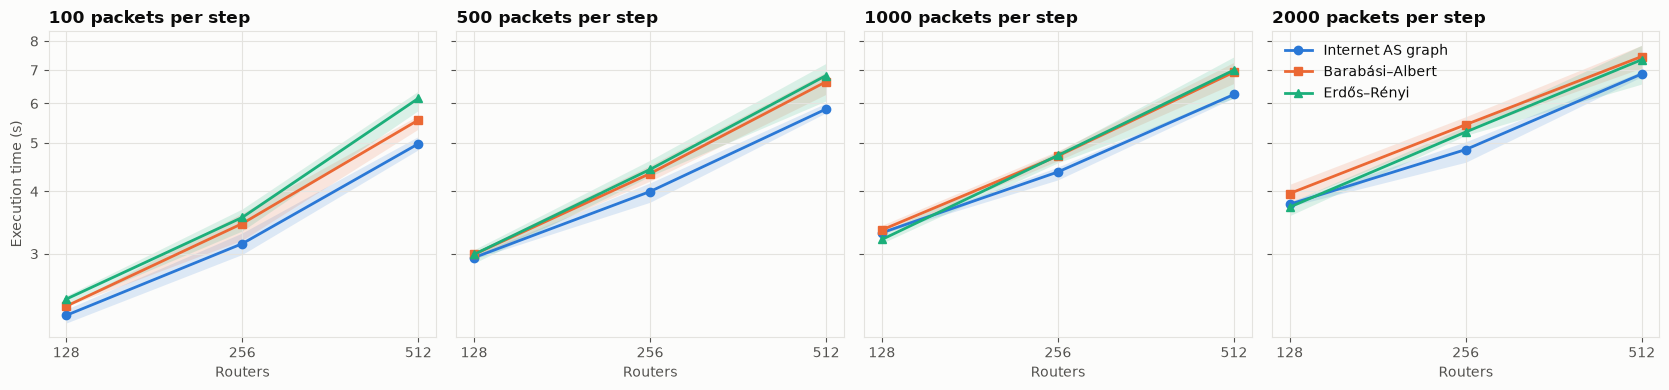

packets_per_step     100   500   1000  2000
topology    routers                        
internet_as 128      2.26  2.95  3.30  3.77
            256      3.14  4.00  4.37  4.85
            512      4.98  5.85  6.25  6.87
random      128      2.43  2.99  3.20  3.72
            256      3.55  4.43  4.72  5.26
            512      6.14  6.82  7.00  7.34
scale_free  128      2.36  2.99  3.35  3.96
            256      3.45  4.34  4.71  5.44
            512      5.56  6.63  6.93  7.45


In [3]:
fig, axes = plt.subplots(1, len(LOADS), figsize=(4.2 * len(LOADS), 4), sharey=True, squeeze=False)
for ax, load in zip(axes[0], LOADS):
    lines(ax, df[df["packets_per_step"] == load], "routers", "sim_time_s")
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_xticks(SIZES, [str(s) for s in SIZES])
    ax.set_title(f"{load} packets per step", loc="left")
    ax.set_xlabel("Routers")
axes[0][0].set_ylabel("Execution time (s)")
axes[0][-1].legend(loc="upper left")
fig.tight_layout()
plt.show()

print(df.pivot_table(index=["topology", "routers"], columns="packets_per_step",
                     values="sim_time_s", aggfunc="mean").round(2).to_string())

## 3. Where the time goes

The routing time is split into the first step, which also builds the forwarding tables,
and the other steps, which forward the packets. The rest of the execution time is spent
by the ECLYPSE framework (simulation loop and placement checks). Heaviest traffic only.

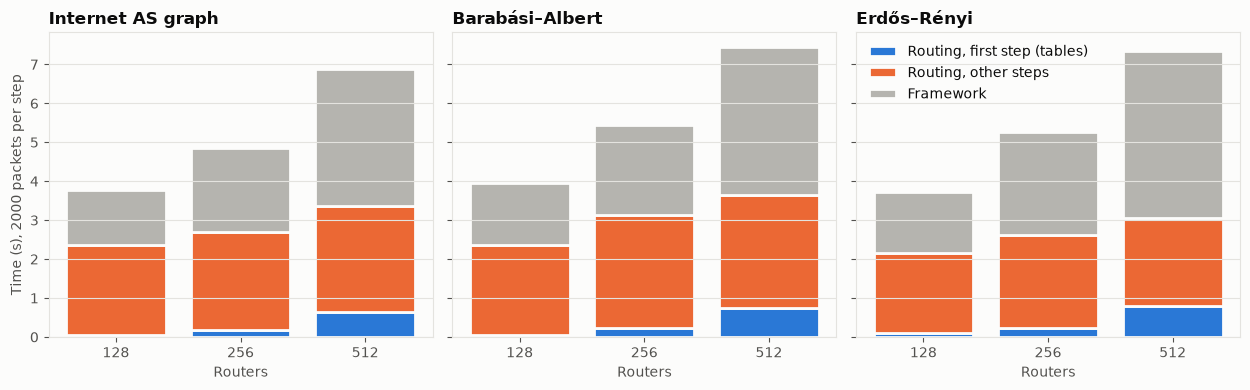

In [4]:
heavy = df[df["packets_per_step"] == max(LOADS)].copy()
heavy["routing_other_s"] = heavy["routing_time_s"] - heavy["routing_first_step_s"]
heavy["framework_s"] = heavy["sim_time_s"] - heavy["routing_time_s"]
parts = {
    "routing_first_step_s": ("Routing, first step (tables)", "#2a78d6"),
    "routing_other_s": ("Routing, other steps", "#eb6834"),
    "framework_s": ("Framework", "#b5b4af"),
}
mean = heavy.groupby(["topology", "routers"])[list(parts)].mean()

fig, axes = plt.subplots(1, len(TOPOLOGIES), figsize=(4.2 * len(TOPOLOGIES), 4), sharey=True)
for ax, topology in zip(axes, TOPOLOGIES):
    if topology not in mean.index.get_level_values(0):
        ax.set_visible(False)
        continue
    m = mean.loc[topology]
    x = np.arange(len(m))
    bottom = np.zeros(len(m))
    for column, (label, color) in parts.items():
        ax.bar(x, m[column], bottom=bottom, color=color, edgecolor=SURFACE, linewidth=2, label=label)
        bottom += m[column].to_numpy()
    ax.set_xticks(x, [str(s) for s in m.index])
    ax.set_xlabel("Routers")
    ax.set_title(TOPOLOGIES[topology]["label"], loc="left")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel(f"Time (s), {max(LOADS)} packets per step")
axes[-1].legend(loc="upper left")
fig.tight_layout()
plt.show()

## 4. Simulation throughput

Hops simulated per second of routing time, excluding the first step. Forwarding is
vectorised over the packets of a step, so the throughput grows with the traffic.

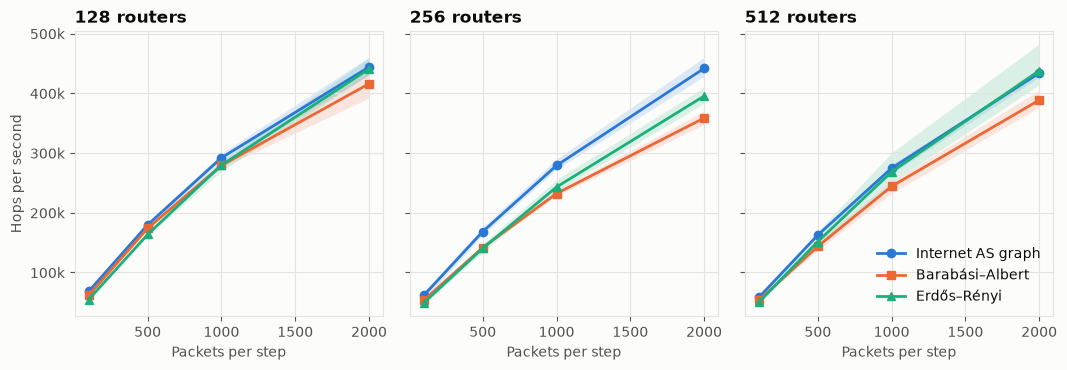

In [5]:
fig, axes = plt.subplots(1, len(SIZES), figsize=(3.6 * len(SIZES), 3.8), sharey=True, squeeze=False)
for ax, size in zip(axes[0], SIZES):
    lines(ax, df[df["routers"] == size], "packets_per_step", "hops_per_s")
    ax.set_title(f"{size} routers", loc="left")
    ax.set_xlabel("Packets per step")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1e3:.0f}k")
axes[0][0].set_ylabel("Hops per second")
axes[0][-1].legend(loc="lower right")
fig.tight_layout()
plt.show()

## 5. Packets: drops and latency

Left: the share of the generated packets that are dropped because a queue is full.
Right: the 95th percentile of the end-to-end latency of the delivered packets.
Largest network only.

The latency includes the time a packet waits in a router until the next step, since
it moves at most one hop per step: with steps of 10 ms, it is mostly the number of
hops times the step duration, plus the propagation of long links (2000 km for the
Tier-1 links of the Internet AS graph). Packets still travelling when the simulation
ends are neither delivered nor dropped (`in_transit_at_end`).

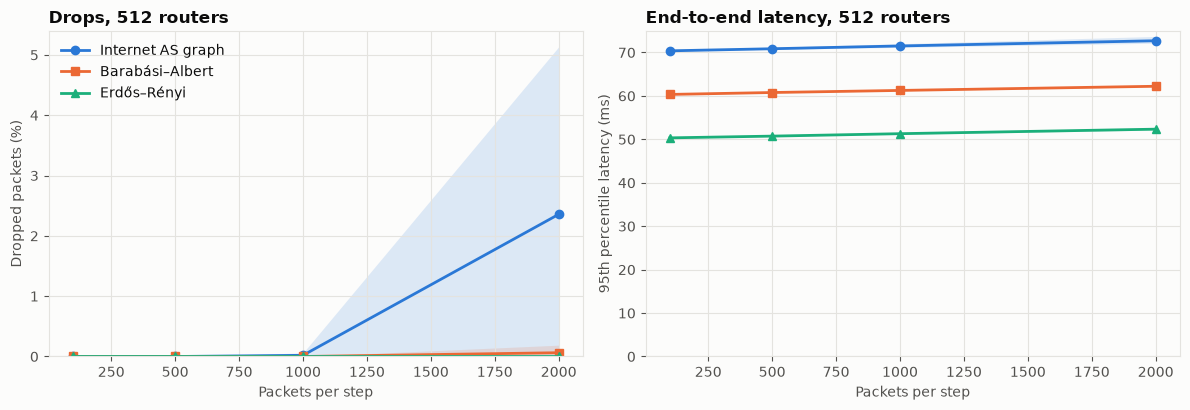

                                      delivery_ratio  dropped_ratio  in_transit_ratio  latency_mean_ms  latency_p95_ms  path_hops_mean
topology    routers packets_per_step                                                                                                  
internet_as 128     100                        0.951          0.000             0.049           48.383          63.718           5.570
                    500                        0.952          0.000             0.048           48.841          64.358           5.571
                    1000                       0.945          0.008             0.047           49.351          65.078           5.564
                    2000                       0.851          0.104             0.045           50.056          66.572           5.528
            256     100                        0.947          0.000             0.053           51.553          70.265           5.850
                    500                        0.949   

In [6]:
largest = df[df["routers"] == max(SIZES)]
fig, (ax_drop, ax_lat) = plt.subplots(1, 2, figsize=(12, 4.2))
lines(ax_drop, largest.assign(dropped_pct=100 * largest["dropped_ratio"]), "packets_per_step", "dropped_pct")
ax_drop.set_xlabel("Packets per step")
ax_drop.set_ylabel("Dropped packets (%)")
ax_drop.set_title(f"Drops, {max(SIZES)} routers", loc="left")
ax_drop.set_ylim(bottom=0)
ax_drop.legend(loc="upper left")

lines(ax_lat, largest, "packets_per_step", "latency_p95_ms")
ax_lat.set_xlabel("Packets per step")
ax_lat.set_ylabel("95th percentile latency (ms)")
ax_lat.set_title(f"End-to-end latency, {max(SIZES)} routers", loc="left")
ax_lat.set_ylim(bottom=0)
fig.tight_layout()
plt.show()

summary = df.groupby(["topology", "routers", "packets_per_step"])[
    ["delivery_ratio", "dropped_ratio", "in_transit_ratio", "latency_mean_ms", "latency_p95_ms", "path_hops_mean"]
].mean()
print(summary.round(3).to_string())

## Notes

- **Capacities differ between topologies.** The builders keep their defaults: in the
  Internet AS graph, links range from 1 Gbps (customers) to 100 Gbps (Tier-1) and are
  up to 2000 km long; in the other two, router links are 1 Gbps and 10 km long. Drops
  and latency therefore depend on these choices as much as on the structure.
- **Equal-cost paths.** Links of the same class have the same cost, so many pairs of
  routers have several shortest paths; the one used depends on the library that
  computes them. Aggregate results are stable, the load of single links is not.
- **Erdős–Rényi density.** `p = er_degree_factor · ln(n) / n` keeps the random graphs
  connected with high probability, so their mean degree grows with the size, while the
  Barabási–Albert graphs keep a mean degree of `2 · ba_m`.